# 03 · Matrix Factorization

Matrix factorization is **compression**. Take the enormous, mostly-empty table of
who-rated-what and factor it into two small tables: a handful of hidden "taste"
dimensions per user, and the same dimensions per item. Multiply a user's vector by
an item's vector (a dot product) and you predict a rating. The hidden dimensions
are *learned*, not labelled — and they end up capturing taste. **That is the
embeddings idea applied to users and items,** trained with the gradient descent you
already know.

We do three things: (1) prove it recovers *planted* structure on synthetic data,
(2) show real item embeddings cluster by genre nobody labelled, and (3) meet the
famous, humbling gap — MF predicts ratings beautifully yet, trained this way, **loses
to the popularity baseline at top-N ranking.**

In [1]:
# --- make the notebook runnable from anywhere: find the repo root, add to path, chdir ---
import os
import sys
from pathlib import Path

_root = Path.cwd()
while not (_root / "pyproject.toml").exists() and _root != _root.parent:
    _root = _root.parent
sys.path.insert(0, str(_root))
os.chdir(_root)

%matplotlib inline
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 120)

from src.artifacts import save_figure, save_json
from src.config import get_settings

SETTINGS = get_settings()
print("project root:", _root)
print("seed:", SETTINGS.seed, "| top_k:", SETTINGS.top_k)

project root: /workspaces/recommender_101
seed: 42 | top_k: 10


## 1. Sanity check: recover known structure

Before trusting MF on real data, point it at synthetic ratings with a *known*
planted group structure. If MF works, its predictions on entries it never saw
should line up with the ground truth.

correlation of MF predictions with ground truth on unseen entries: 0.993


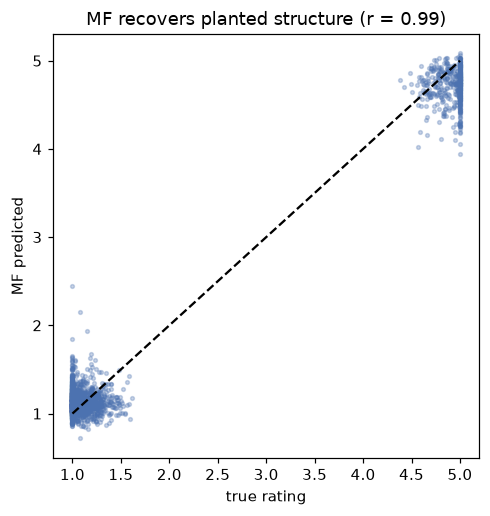

In [2]:
from src.data.ratings import make_synthetic_ratings
from src.recommenders.matrix_factorization import MatrixFactorization

syn = make_synthetic_ratings(n_users=120, n_items=80, n_groups=4, density=0.25, noise=0.2, seed=7)
mf_syn = MatrixFactorization(n_factors=8, n_epochs=60, lr=0.02, reg=0.02, seed=0).fit(syn.observed)

predicted = mf_syn.reconstruct()
held = syn.observed.toarray() == 0
true_vals, pred_vals = syn.true_ratings[held], predicted[held]
corr = float(np.corrcoef(true_vals, pred_vals)[0, 1])
save_json({"heldout_prediction_correlation": corr, "n_heldout": int(held.sum())}, "03_synthetic_recovery")
print(f"correlation of MF predictions with ground truth on unseen entries: {corr:.3f}")

idx = np.random.default_rng(0).choice(len(true_vals), size=min(2000, len(true_vals)), replace=False)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(true_vals[idx], pred_vals[idx], s=6, alpha=0.3, color="#4C72B0")
ax.plot([1, 5], [1, 5], "--", color="black")
ax.set_xlabel("true rating")
ax.set_ylabel("MF predicted")
ax.set_title(f"MF recovers planted structure (r = {corr:.2f})")
save_figure(fig, "03_synthetic_recovery")
plt.show()

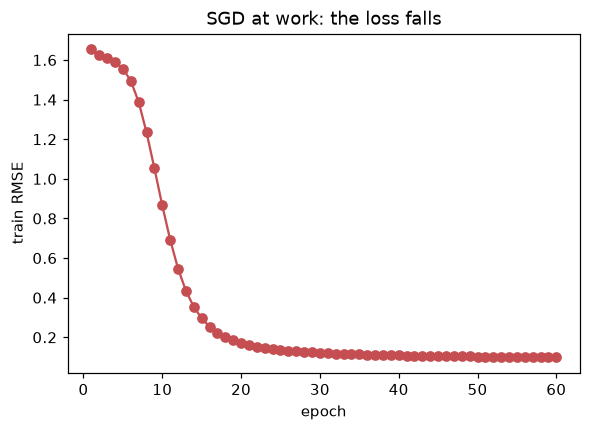

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(1, len(mf_syn.history_) + 1), mf_syn.history_, marker="o", color="#C44E52")
ax.set_xlabel("epoch")
ax.set_ylabel("train RMSE")
ax.set_title("SGD at work: the loss falls")
save_figure(fig, "03_training_loss")
plt.show()

## 2. On real data, the dimensions capture taste

Train MF on MovieLens, project the learned 32-dimensional *item* embeddings down to
2-D, and colour each movie by its primary genre. Movies cluster by genre — even
though **MF never saw a single genre label.** The taste structure is implied
entirely by who rated what.

In [4]:
from sklearn.decomposition import PCA

from src.data.ratings import load_movielens
from src.evaluation.splits import leave_last_out

data = load_movielens()
matrix, titles = data.matrix, (data.item_titles or [])
genres = data.genre_names or []
features = data.item_features
split = leave_last_out(
    matrix, n_holdout=SETTINGS.split.n_holdout, min_train=SETTINGS.split.min_train,
    timestamps=data.timestamps, seed=SETTINGS.seed,
)
mf = MatrixFactorization(
    n_factors=SETTINGS.mf.n_factors, n_epochs=SETTINGS.mf.n_epochs,
    lr=SETTINGS.mf.lr, reg=SETTINGS.mf.reg, use_bias=SETTINGS.mf.use_bias, seed=SETTINGS.seed,
).fit(split.train)
save_json({"epoch": list(range(1, len(mf.history_) + 1)), "train_rmse": mf.history_}, "03_mf_training_history")
print("final train RMSE:", round(mf.history_[-1], 4))

final train RMSE: 0.5758


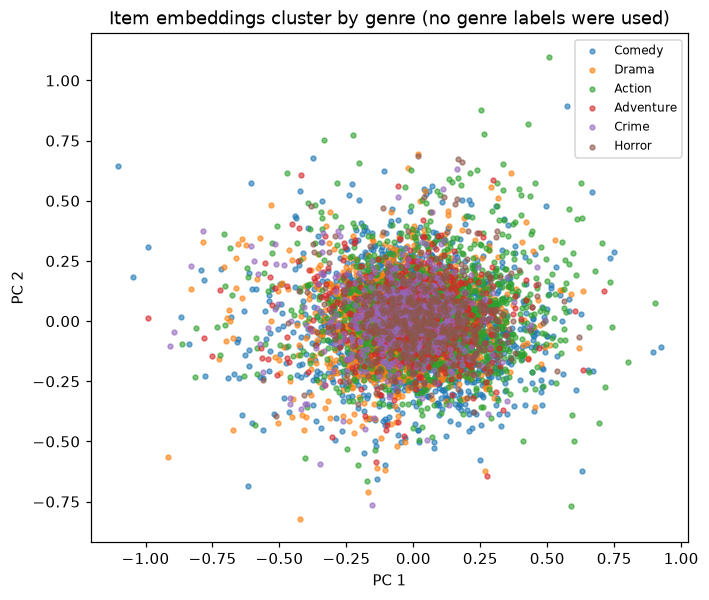

In [5]:
# primary genre per item (argmax of the multi-hot feature row); skip genre-less items
feat = features.toarray()
has_genre = feat.sum(axis=1) > 0
primary = feat.argmax(axis=1)

# only plot the most common genres so the colours stay legible
common = pd.Series(primary[has_genre]).value_counts().index[:6].tolist()
mask = has_genre & np.isin(primary, common)

coords = PCA(n_components=2, random_state=SETTINGS.seed).fit_transform(mf.item_factors_[mask])
labels = primary[mask]

fig, ax = plt.subplots(figsize=(7, 6))
for g in common:
    sel = labels == g
    ax.scatter(coords[sel, 0], coords[sel, 1], s=10, alpha=0.6, label=genres[g])
ax.set_title("Item embeddings cluster by genre (no genre labels were used)")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(fontsize=8)
save_figure(fig, "03_item_embedding_genres")
plt.show()

In [6]:
# quantify it: are same-genre items closer in embedding space than random pairs?
from sklearn.preprocessing import normalize

normed = normalize(mf.item_factors_[has_genre])
prim = primary[has_genre]
rng = np.random.default_rng(SETTINGS.seed)
sample = rng.choice(len(prim), size=4000, replace=True)
a, b = sample[::2], sample[1::2]
cos = (normed[a] * normed[b]).sum(axis=1)
same = prim[a] == prim[b]
clustering = {
    "mean_cosine_same_genre": float(cos[same].mean()),
    "mean_cosine_diff_genre": float(cos[~same].mean()),
}
clustering["ratio"] = clustering["mean_cosine_same_genre"] / clustering["mean_cosine_diff_genre"]
save_json(clustering, "03_embedding_genre_clustering")
clustering

{'mean_cosine_same_genre': 0.006988916110584099,
 'mean_cosine_diff_genre': 0.006298014961154089,
 'ratio': 1.109701414444307}

## 3. The humbling gap: great at ratings, weak at ranking

MF is trained to minimise rating-prediction error (RMSE), and it is genuinely good
at that — better than guessing each item's average. But a recommender's job is to
*rank* a top-k list, and there MF — trained this explicit-rating way — **loses to
the popularity baseline.** This is not a bug; it is the well-documented
offline-ranking gap (Cremonesi 2010; Rendle 2020). Optimising the wrong objective
(squared error) does not optimise the thing we actually score (ranking).

In [7]:
from src.evaluation.ranking import evaluate_ranking, recall_at_k
from src.recommenders.popularity import PopularityRecommender

matrix_csr = matrix.tocsr()
col_sum = np.asarray(split.train.sum(axis=0)).ravel()
col_cnt = np.asarray((split.train > 0).sum(axis=0)).ravel()
global_mean = split.train.data.mean()
item_mean = np.where(col_cnt > 0, col_sum / np.maximum(col_cnt, 1), global_mean)

true, mf_pred, mean_pred = [], [], []
for u, items in split.test_items.items():
    for it in items:
        true.append(matrix_csr[u, it]); mf_pred.append(mf.predict(u, int(it))); mean_pred.append(item_mean[it])
true, mf_pred, mean_pred = map(np.array, (true, mf_pred, mean_pred))
rmse = {
    "mf": float(np.sqrt(np.mean((true - mf_pred) ** 2))),
    "item_mean_baseline": float(np.sqrt(np.mean((true - mean_pred) ** 2))),
}

pop = PopularityRecommender().fit(split.train)
k = SETTINGS.top_k
pop_recs, mf_recs = pop.recommend_all(k=k), mf.recommend_all(k=k)
ranking = {
    "popularity": evaluate_ranking(pop_recs, split.test_items, k),
    "matrix_factorization": evaluate_ranking(mf_recs, split.test_items, k),
}
save_json({"heldout_rmse": rmse, "ranking": ranking}, "03_rmse_vs_ranking")
print("held-out RMSE (lower=better):", {kk: round(v, 3) for kk, v in rmse.items()})
print("recall@%d (higher=better): pop=%.4f  mf=%.4f" % (k, ranking["popularity"]["recall@k"], ranking["matrix_factorization"]["recall@k"]))

held-out RMSE (lower=better): {'mf': 0.933, 'item_mean_baseline': 1.036}
recall@10 (higher=better): pop=0.0361  mf=0.0107


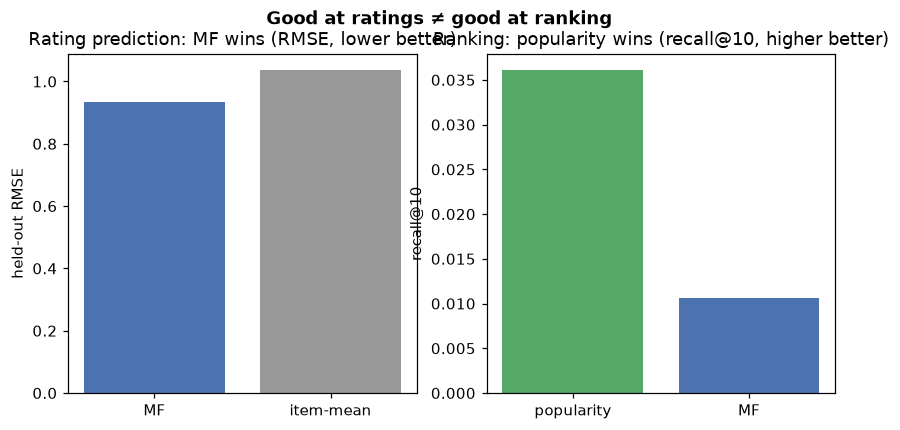

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))
ax1.bar(["MF", "item-mean"], [rmse["mf"], rmse["item_mean_baseline"]], color=["#4C72B0", "#999999"])
ax1.set_title("Rating prediction: MF wins (RMSE, lower better)")
ax1.set_ylabel("held-out RMSE")
ax2.bar(["popularity", "MF"], [ranking["popularity"]["recall@k"], ranking["matrix_factorization"]["recall@k"]],
        color=["#55A868", "#4C72B0"])
ax2.set_title(f"Ranking: popularity wins (recall@{k}, higher better)")
ax2.set_ylabel(f"recall@{k}")
fig.suptitle("Good at ratings ≠ good at ranking", fontweight="bold")
save_figure(fig, "03_rmse_vs_ranking")
plt.show()

## Takeaway

MF compresses the ratings matrix into interpretable-ish taste embeddings and
predicts ratings better than any per-item average — a real achievement. Yet the
**fancy method loses to "most popular" at the top-k task we actually care about.**
That is the title of this project, demonstrated. The fix is to train for ranking
on implicit (liked / not-liked) signals rather than explicit rating values — the
road to BPR / ALS flagged in the project's future work.

**Next:** [04 · The Arena](04_arena.ipynb) — all five methods against popularity
across every metric, including the beyond-accuracy ones that change the verdict.